In [1]:
import pandas as pd, numpy as np, json, time, warnings
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
                             precision_recall_curve, confusion_matrix)
from sklearn.inspection import permutation_importance
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 60)

FEATURES = ['first_exact','first_jw','first_nick','first_initial','last_exact','last_jw','last_lev','last_sdx_eq',
            'email_exact','email_jw','email_lev','email_digits_eq','email_domain_eq','phone_eq',
            'addr_exact','addr_lev','addr_jw','house_eq','zip_eq','city_eq',
            'miss_email','miss_phone','miss_addr','cross_system']
dtypes = {f: 'float32' for f in FEATURES}; dtypes.update({'label': 'int8', 'idx_a': 'int32', 'idx_b': 'int32'})
df = pd.read_csv('pair_features.csv', usecols=FEATURES + ['idx_a','idx_b','tid_a','tid_b','label'], dtype=dtypes)
print(df.shape, '| positive rate', round(df.label.mean(), 4))

(784350, 29) | positive rate 0.1504


## 1. Test set and development set (split by customer)
Records of one customer give strongly related pairs (A-B, A-C, B-C). If one went to train and another to test, the score would be inflated. So whole **customers** are assigned to a set: 80% development (used for cross-validation), 20% test. Each pair goes to the set of its first record's customer.

*Small caveat:* a non-duplicate pair (A, B) is placed by A's customer, so B's customer may sit in the other set. The models only see similarity scores, not identities, so this leak is very weak, and it keeps the real 15% class balance.

In [2]:
cats = pd.Index(pd.unique(pd.concat([df.tid_a, df.tid_b])))
ca = cats.get_indexer(df.tid_a)                          # integer id of the customer of record A
rng = np.random.RandomState(42)
is_test_customer = rng.rand(len(cats)) < 0.20
te = is_test_customer[ca]; dev = ~te

X, y = df[FEATURES], df.label.values
Xd, yd, gd = X[dev].reset_index(drop=True), y[dev], ca[dev]      # development set + group (customer) ids
Xte, yte = X[te], y[te]
print(pd.DataFrame({'pairs': [dev.sum(), te.sum()], 'positives': [yd.sum(), yte.sum()],
                    'positive_rate': [yd.mean(), yte.mean()]}, index=['development', 'test']).round(4))

              pairs  positives  positive_rate
development  628937      94630         0.1505
test         155413      23358         0.1503


## 2. Helper functions and a rule baseline
Baseline rule: "same customer if the email name part or the phone matches exactly". Every model must beat it.

In [3]:
def metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return dict(precision=precision_score(y_true, pred), recall=recall_score(y_true, pred), F1=f1_score(y_true, pred),
                PR_AUC=average_precision_score(y_true, proba), ROC_AUC=roc_auc_score(y_true, proba))

rule_te = ((Xte.email_exact == 1) | (Xte.phone_eq == 1)).astype(int).values
rule = {'precision': precision_score(yte, rule_te), 'recall': recall_score(yte, rule_te), 'F1': f1_score(yte, rule_te)}
print('Rule baseline on TEST (email_exact OR phone_eq):', {k: round(v, 4) for k, v in rule.items()})

Rule baseline on TEST (email_exact OR phone_eq): {'precision': 0.856, 'recall': 0.918, 'F1': 0.8859}


## 3. The models
| Model | Idea | Notes |
|---|---|---|
| **Logistic regression** | one weighted sum of the scores | simple, explainable; needs filled `NaN` (0 + "was missing" flag) and scaling; `class_weight='balanced'` for the 85/15 imbalance |
| **Decision tree** | a single set of if/then rules | readable, but unstable; depth limited |
| **Random forest** | 100 trees voting | robust, handles interactions; slower |
| **Gradient boosting** (`HistGradientBoosting`) | trees built one after another, each fixing the previous errors | usually strongest on tabular data; accepts `NaN` directly |
| **XGBoost / LightGBM** | optional, same family as gradient boosting | used only if installed (`pip install xgboost lightgbm`) |

For the tree models `NaN` is replaced by **-1**, a value no similarity can take, so "missing" becomes its own branch.

In [4]:
fill_m1 = lambda: SimpleImputer(strategy='constant', fill_value=-1)
MODELS = {
  'Logistic regression': lambda: Pipeline([('imp', SimpleImputer(strategy='constant', fill_value=0, add_indicator=True)),
                                           ('sc', StandardScaler()),
                                           ('m', LogisticRegression(max_iter=2000, class_weight='balanced'))]),
  'Decision tree':       lambda: Pipeline([('imp', fill_m1()), ('m', DecisionTreeClassifier(max_depth=14, min_samples_leaf=5, random_state=42))]),
  'Random forest':       lambda: Pipeline([('imp', fill_m1()), ('m', RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=3, n_jobs=-1, random_state=42))]),
  'Gradient boosting':   lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, max_leaf_nodes=31, early_stopping=True,
                                                                validation_fraction=0.1, n_iter_no_change=15, random_state=42),
}
try:
    from xgboost import XGBClassifier
    MODELS['XGBoost'] = lambda: XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, tree_method='hist', eval_metric='logloss', n_jobs=-1, random_state=42)
except ImportError: print('xgboost not installed - skipped (pip install xgboost)')
try:
    from lightgbm import LGBMClassifier
    MODELS['LightGBM'] = lambda: LGBMClassifier(n_estimators=300, learning_rate=0.1, num_leaves=31, n_jobs=-1, random_state=42, verbose=-1)
except ImportError: print('lightgbm not installed - skipped (pip install lightgbm)')
print('models:', list(MODELS))

models: ['Logistic regression', 'Decision tree', 'Random forest', 'Gradient boosting', 'XGBoost', 'LightGBM']


## 4. 3-fold cross-validation, grouped by customer
`GroupKFold(n_splits=3)` splits the **customers** into 3 parts. Each model is trained on 2 parts and scored on the third, three times, so every pair gets one **out-of-fold** prediction from a model that never saw its customer. The mean and the spread (std) of the 3 scores show whether a difference between models is real or just luck.

*Note:* with only 3 folds each model trains on about 2/3 of the development data and the std is estimated from only 3 numbers, so treat it as a rough guide.

In [5]:
folds = list(GroupKFold(n_splits=3).split(Xd, yd, gd))
oof = {n: np.zeros(len(Xd)) for n in MODELS}
rows = []
for name, make in MODELS.items():
    for k, (i_tr, i_va) in enumerate(folds, 1):
        t = time.time()
        m = make().fit(Xd.iloc[i_tr], yd[i_tr])
        pr = m.predict_proba(Xd.iloc[i_va])[:, 1]; oof[name][i_va] = pr
        rows.append({'model': name, 'fold': k, **metrics(yd[i_va], pr), 'fit_sec': time.time() - t})
    print(f'{name:22s} done | mean F1 {np.mean([r["F1"] for r in rows if r["model"]==name]):.4f}')
cv = pd.DataFrame(rows)

Logistic regression    done | mean F1 0.9955
Decision tree          done | mean F1 0.9973
Random forest          done | mean F1 0.9981
Gradient boosting      done | mean F1 0.9982
XGBoost                done | mean F1 0.9984
LightGBM               done | mean F1 0.9983


3-fold grouped CV on the development set (mean +/- std over folds, threshold 0.5)


,precision,recall,F1,PR_AUC,ROC_AUC,fit_sec
model,,,,,,
XGBoost,0.9983 +/- 0.0002,0.9984 +/- 0.0002,0.9984 +/- 0.0001,1.0000 +/- 0.0000,1.0000,24.0
LightGBM,0.9982 +/- 0.0002,0.9983 +/- 0.0003,0.9983 +/- 0.0003,1.0000 +/- 0.0000,1.0000,17.5
Gradient boosting,0.9982 +/- 0.0003,0.9982 +/- 0.0001,0.9982 +/- 0.0002,1.0000 +/- 0.0000,1.0000,18.7
Random forest,0.9979 +/- 0.0003,0.9983 +/- 0.0001,0.9981 +/- 0.0002,0.9999 +/- 0.0001,1.0000,39.3
Decision tree,0.9972 +/- 0.0001,0.9975 +/- 0.0003,0.9973 +/- 0.0002,0.9979 +/- 0.0003,0.9994,3.8
Logistic regression,0.9916 +/- 0.0012,0.9995 +/- 0.0003,0.9955 +/- 0.0004,0.9999 +/- 0.0000,1.0000,6.4


Per-fold F1:


fold,1,2,3
model,,,
Decision tree,0.9974,0.9971,0.9975
Gradient boosting,0.9984,0.9982,0.9980
LightGBM,0.9985,0.9982,0.9980
Logistic regression,0.9960,0.9954,0.9952
Random forest,0.9983,0.9980,0.9980
XGBoost,0.9985,0.9983,0.9983


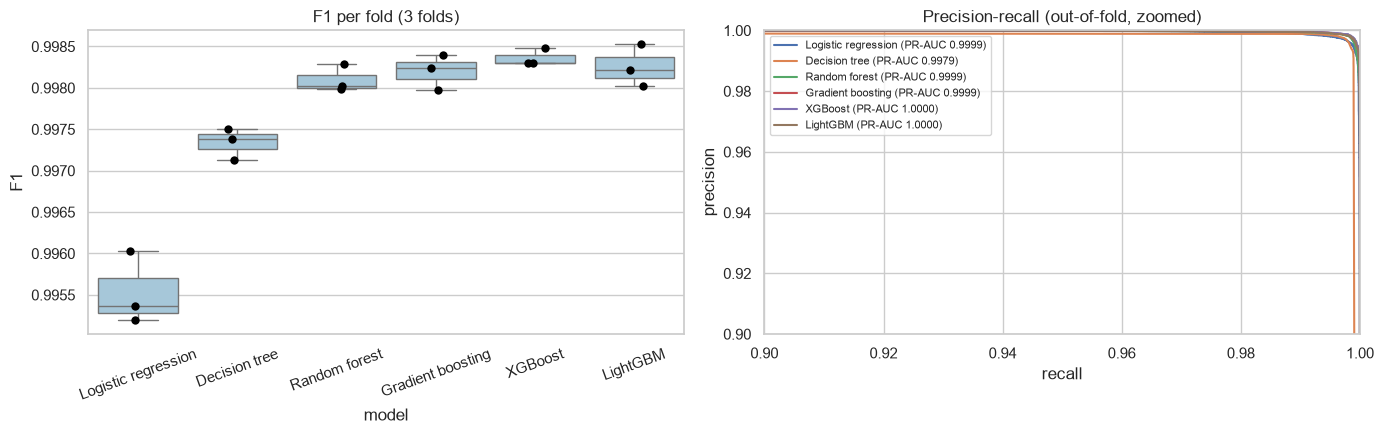

In [6]:
mean = cv.groupby('model')[['precision','recall','F1','PR_AUC','ROC_AUC','fit_sec']].mean()
std = cv.groupby('model')[['precision','recall','F1','PR_AUC']].std()
summary = mean.copy()
for c_ in ['precision','recall','F1','PR_AUC']:
    summary[c_] = [f'{m:.4f} +/- {s:.4f}' for m, s in zip(mean[c_], std[c_])]
summary['ROC_AUC'] = mean.ROC_AUC.round(4); summary['fit_sec'] = mean.fit_sec.round(1)
print('3-fold grouped CV on the development set (mean +/- std over folds, threshold 0.5)')
display(summary.loc[mean.sort_values('F1', ascending=False).index])
print('Per-fold F1:')
display(cv.pivot(index='model', columns='fold', values='F1').round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=cv, x='model', y='F1', ax=ax[0], color='#9ecae1'); sns.stripplot(data=cv, x='model', y='F1', ax=ax[0], color='black', size=6)
ax[0].set_title('F1 per fold (3 folds)'); ax[0].tick_params(axis='x', rotation=20)
for n_, v in oof.items():
    pp, rr, _ = precision_recall_curve(yd, v); ax[1].plot(rr, pp, label=f'{n_} (PR-AUC {average_precision_score(yd, v):.4f})')
ax[1].set_xlim(0.9, 1.0); ax[1].set_ylim(0.9, 1.0); ax[1].set_xlabel('recall'); ax[1].set_ylabel('precision')
ax[1].set_title('Precision-recall (out-of-fold, zoomed)'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Pick the best model and the threshold
Best model = highest mean CV F1 (ties are broken by PR-AUC). A model outputs a probability; the **threshold** turns it into "same / different":
- **Higher threshold** -> fewer wrong merges (high precision), more missed duplicates.
- **Lower threshold** -> finds more duplicates, more wrong merges.

The thresholds are chosen on the **out-of-fold** predictions of the winner (never on the test set): the one with the best F1, and the lowest one that keeps precision at 99.9% ("safe merge": about 1 wrong merge in 1,000).

Best model by mean CV F1: XGBoost
threshold for best F1: 0.471 | threshold for precision >= 99.9%: 0.863


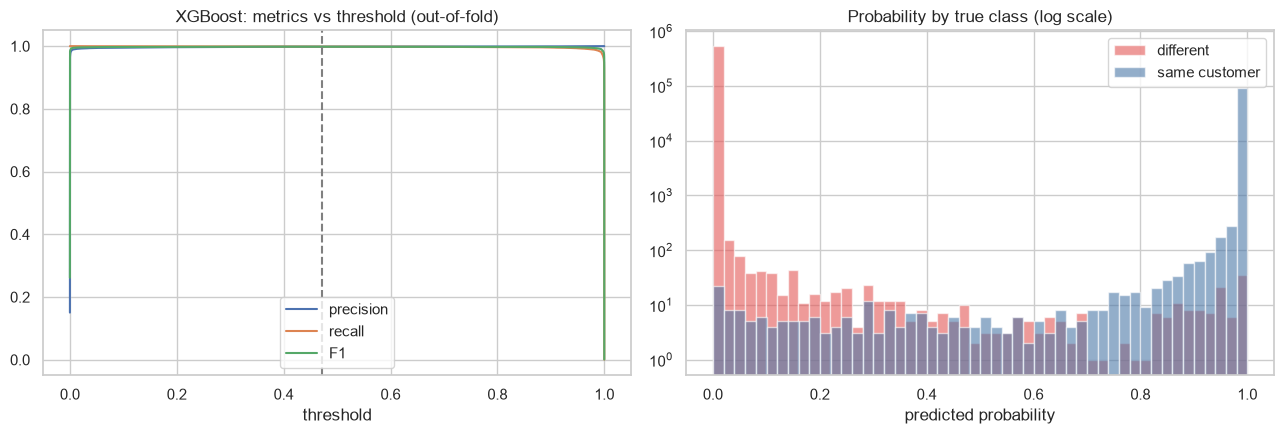

In [7]:
best = mean.sort_values(['F1', 'PR_AUC'], ascending=False).index[0]
print('Best model by mean CV F1:', best)
p, r, th = precision_recall_curve(yd, oof[best])
f1s = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
thr_f1 = float(th[np.argmax(f1s)])
ok = np.where(p[:-1] >= 0.999)[0]
thr_safe = float(th[ok[0]]) if len(ok) else 0.99
print(f'threshold for best F1: {thr_f1:.3f} | threshold for precision >= 99.9%: {thr_safe:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(th, p[:-1], label='precision'); ax[0].plot(th, r[:-1], label='recall'); ax[0].plot(th, f1s, label='F1')
ax[0].axvline(thr_f1, color='grey', ls='--'); ax[0].set_xlabel('threshold'); ax[0].set_title(f'{best}: metrics vs threshold (out-of-fold)'); ax[0].legend()
for lab, colr, nm in [(0, '#E45756', 'different'), (1, '#4C78A8', 'same customer')]:
    ax[1].hist(oof[best][yd == lab], bins=50, alpha=.6, color=colr, label=nm, log=True)
ax[1].set_xlabel('predicted probability'); ax[1].set_title('Probability by true class (log scale)'); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Final evaluation on the untouched TEST set
Every model is refitted on the whole development set and scored once on the test customers.

In [8]:
fitted, pt = {}, {}
for name, make in MODELS.items():
    t = time.time(); fitted[name] = make().fit(Xd, yd); pt[name] = fitted[name].predict_proba(Xte)[:, 1]
    print(f'{name:22s} refitted in {time.time()-t:.0f}s')

rows = {'Rule baseline (email OR phone)': {**rule, 'PR_AUC': np.nan, 'ROC_AUC': np.nan}}
for name in MODELS: rows[f'{name} @0.5'] = metrics(yte, pt[name], 0.5)
rows[f'{best} @{thr_f1:.2f} (best F1)'] = metrics(yte, pt[best], thr_f1)
rows[f'{best} @{thr_safe:.2f} (safe merge)'] = metrics(yte, pt[best], thr_safe)
display(pd.DataFrame(rows).T.round(4))

cm = confusion_matrix(yte, (pt[best] >= thr_f1).astype(int))
print(f'Confusion matrix for {best} at the best-F1 threshold (rows = truth, columns = prediction):')
display(pd.DataFrame(cm, index=['truth: different', 'truth: same'], columns=['pred: different', 'pred: same']))

Logistic regression    refitted in 9s
Decision tree          refitted in 6s
Random forest          refitted in 52s
Gradient boosting      refitted in 19s
XGBoost                refitted in 32s
LightGBM               refitted in 19s


,precision,recall,F1,PR_AUC,ROC_AUC
Rule baseline (email OR phone),0.8560,0.9180,0.8859,NaN,NaN
Logistic regression @0.5,0.9919,0.9990,0.9955,0.9999,1.0000
Decision tree @0.5,0.9976,0.9976,0.9976,0.9985,0.9995
Random forest @0.5,0.9982,0.9984,0.9983,1.0000,1.0000
Gradient boosting @0.5,0.9981,0.9983,0.9982,1.0000,1.0000
XGBoost @0.5,0.9982,0.9984,0.9983,1.0000,1.0000
LightGBM @0.5,0.9980,0.9981,0.9981,1.0000,1.0000
XGBoost @0.47 (best F1),0.9981,0.9984,0.9982,1.0000,1.0000
XGBoost @0.86 (safe merge),0.9991,0.9966,0.9979,1.0000,1.0000


Confusion matrix for XGBoost at the best-F1 threshold (rows = truth, columns = prediction):


,pred: different,pred: same
truth: different,132010,45
truth: same,38,23320


## 7. Which features matter?
**Permutation importance:** shuffle one feature and see how much PR-AUC drops. A big drop = the model relies on it. Features that are close copies of each other (`email_jw` and `email_lev`) share the credit, so each one looks smaller than it really is.

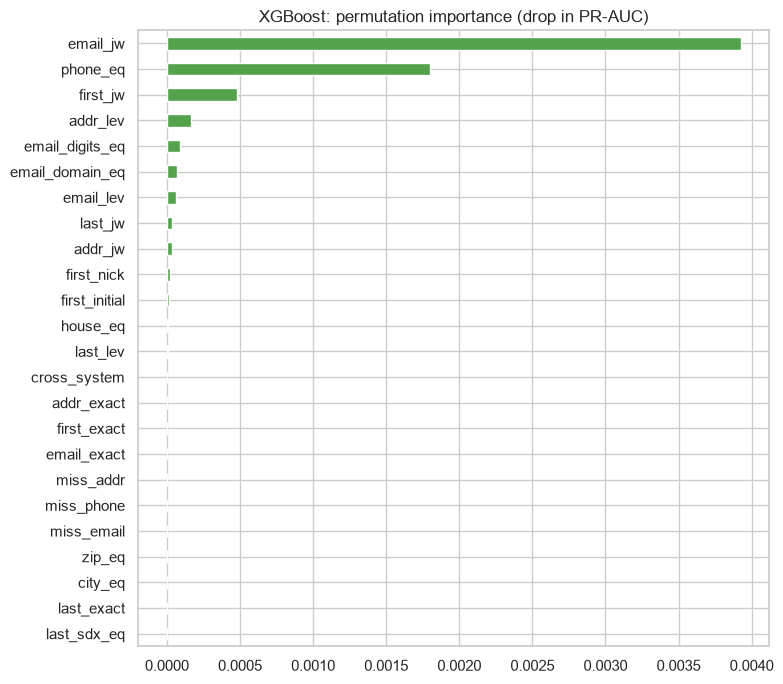

email_jw           0.0039
phone_eq           0.0018
first_jw           0.0005
addr_lev           0.0002
email_digits_eq    0.0001
email_domain_eq    0.0001
email_lev          0.0001
last_jw            0.0000
addr_jw            0.0000
first_nick         0.0000
dtype: float64


In [9]:
model = fitted[best]
idx = np.random.RandomState(0).choice(len(Xte), size=min(40000, len(Xte)), replace=False)
pi = permutation_importance(model, Xte.iloc[idx], yte[idx], scoring='average_precision', n_repeats=3, random_state=0, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.plot.barh(figsize=(8, 7), color='#54A24B'); plt.title(f'{best}: permutation importance (drop in PR-AUC)'); plt.tight_layout(); plt.show()
print(imp.sort_values(ascending=False).round(4).head(10))

## 8. Ablation: do the weak features help?
Train the best model type on smaller feature sets (development set) and compare on the test set. If a set performs the same, the dropped features are not needed.

In [10]:
sets = {'all 24 features': FEATURES,
        'drop zip/city/cross_system': [f for f in FEATURES if f not in ('zip_eq', 'city_eq', 'cross_system')],
        'drop missing flags': [f for f in FEATURES if not f.startswith('miss_')],
        'name + email only': [f for f in FEATURES if f.startswith(('first', 'last', 'email'))],
        'phone + address only': ['phone_eq','addr_exact','addr_lev','addr_jw','house_eq','zip_eq','city_eq']}
rows = {}
for nm, cols in sets.items():
    m = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, random_state=42).fit(Xd[cols], yd)
    rows[nm] = {**metrics(yte, m.predict_proba(Xte[cols])[:, 1], 0.5), 'n_features': len(cols)}
pd.DataFrame(rows).T.round(4)

,precision,recall,F1,PR_AUC,ROC_AUC,n_features
all 24 features,0.9981,0.9983,0.9982,1.0000,1.0000,24.0
drop zip/city/cross_system,0.9981,0.9982,0.9981,1.0000,1.0000,21.0
drop missing flags,0.9981,0.9983,0.9982,1.0000,1.0000,21.0
name + email only,0.9931,0.9870,0.9900,0.9995,0.9999,13.0
phone + address only,0.8696,0.7385,0.7987,0.7933,0.9713,7.0


## 9. Error analysis: what does the best model get wrong?

In [11]:
nm_df = pd.read_csv('cleaned_customers.csv', usecols=['record_id', 'full_name', 'email', 'phone', 'address'], keep_default_na=False, na_values=[''])
T = df[te].copy(); T['proba'] = pt[best]
def show(frame):
    a, b = nm_df.iloc[frame.idx_a.values].reset_index(drop=True), nm_df.iloc[frame.idx_b.values].reset_index(drop=True)
    return pd.DataFrame({'name_a': a.full_name, 'name_b': b.full_name, 'email_a': a.email, 'email_b': b.email,
                         'phone_a': a.phone, 'phone_b': b.phone, 'proba': frame.proba.values}).round(3)
print('MISSED duplicates (truth = same, lowest probability):')
display(show(T[T.label == 1].sort_values('proba').head(8)))
print('WRONG merges (truth = different, highest probability):')
display(show(T[T.label == 0].sort_values('proba', ascending=False).head(8)))

MISSED duplicates (truth = same, lowest probability):


,name_a,name_b,email_a,email_b,phone_a,phone_b,proba
0,Joe Ann Shaeffers,SHAEFFES JOE ANN,joeann.shaeffers76@example.org,NaN,(336) 584-9145,3365849145,0.000
1,Joe Ann Shaeffers,SHAEFFES JOE ANN,joeann.sheffers76@example.org,NaN,(336) 584-9145,3365849145,0.000
2,Alex Jarrell,Alemander Jarrell,alexanderrjarrell43@inbox.example,NaN,NaN,NaN,0.005
3,Chuck Bradsher,BRADSHER CHVRLES,charles.bradsher58@post.example,NaN,(757) 288-9529,757-288-9529,0.014
4,P. Jackson,P. Jackson,pjackson3@example.org,pzackson13@example.org,NaN,NaN,0.014
5,Pamela Lucas,"Lucas, Pamela",plucas72@example.org,plucasp2@mail.example,3364371647,3364371647,0.019
6,William Shannon,B. Shannon,williamshannon30@mail.example,NaN,(336) 534-5481,(336) 534-5481,0.025
7,La Vonda Street,"Street, Ln Vonda",lavonda_street72@mail.example,NaN,NaN,NaN,0.029


WRONG merges (truth = different, highest probability):


,name_a,name_b,email_a,email_b,phone_a,phone_b,proba
0,ALBRIGHT JAMES,ALBRIGHT JIM,james.albright89@post.example,jamesalbright89@example.net,NaN,3365125424,1.000
1,Ronald Carter,R. Carter,ronald.carter93@mail.example,ronaldcartre37@mail.example,(919) 332-0383,919-332-0383,0.995
2,Saroeun Phoeung,S. Phoeung,saroeun_phoeung71@inbox.example,NaN,(215) 930-3364,215-930-3364,0.991
3,Salong Phoeung,S. Phoeung,salong_phoeung38@example.com,NaN,(215) 930-3364,215-930-3364,0.991
4,Cladia I. Galvez,"Galvez, Clauddia",NaN,cgalvez21@mail.example,NaN,+1 336 290 4031,0.987
5,Michael Minichiello,M. Minichiello,michael_minichiello76@example.org,NaN,(336) 524-6670,3365246670,0.986
6,Claudia Galvez,Cladia I. Galvez,cgalvez21@mail.example,NaN,(336) 290-4031,NaN,0.979
7,R. Newkirt,Roosevelt Newkirt,roosevelt_newkirt72@post.example,roosevelt.newkirt24@post.example,3364474160,(336) 447-4160,0.977


## 10. Save the model and the predictions for Step 5
Step 5 builds customer groups from the pairs we call "same", so we predict **all** 784,350 pairs with the best model (refitted on the development set).

In [12]:
import joblib
proba_all = model.predict_proba(X)[:, 1]
out = pd.DataFrame({'idx_a': df.idx_a.values, 'idx_b': df.idx_b.values, 'proba': proba_all.astype('float32'),
                    'pred_f1': (proba_all >= thr_f1).astype('int8'), 'pred_safe': (proba_all >= thr_safe).astype('int8'),
                    'label': df.label.values, 'set': np.where(te, 'test', 'development')})
out.to_csv('pair_predictions.csv', index=False)
joblib.dump({'model': model, 'name': best, 'features': FEATURES, 'thr_f1': thr_f1, 'thr_safe': thr_safe}, 'dedup_model.joblib')
json.dump({'model': best, 'thr_f1': thr_f1, 'thr_safe': thr_safe}, open('thresholds.json', 'w'))
cv.to_csv('cv_results.csv', index=False)
print('saved pair_predictions.csv, dedup_model.joblib, thresholds.json, cv_results.csv')
print('pairs predicted "same" at best-F1 threshold:', int(out.pred_f1.sum()), '| at safe threshold:', int(out.pred_safe.sum()), '| true duplicate pairs:', int(out.label.sum()))

saved pair_predictions.csv, dedup_model.joblib, thresholds.json, cv_results.csv
pairs predicted "same" at best-F1 threshold: 118001 | at safe threshold: 117732 | true duplicate pairs: 117988


## 11. Summary and next step
- The 3-fold grouped cross-validation compares models on customers they never saw, and the spread across folds shows how much of a difference is noise.
- If several models are within one std of each other, prefer the simpler or faster one; the final choice here is made automatically by mean CV F1.
- Pick the threshold by business risk: a **wrong merge** loses information about two customers, a **missed duplicate** just leaves a duplicate. If wrong merges are worse, use the safe threshold.
- **Step 5:** build a graph where every pair predicted "same" is an edge, take **connected components** as customers, compare the groups with `true_customer_id`, and merge each group into one golden record.